In [1]:
import pandas as  pd
import numpy as np 
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv(r"C:\Users\LENOVO\Downloads\advertising_nonlinear.csv")

In [3]:
data.head()

,TV,Radio,Newspaper,Sales,Sales_Nonlinear
0,230.1,37.8,69.2,22.1,5.35
1,44.5,39.3,45.1,10.4,7.20
2,17.2,45.9,69.3,12.0,7.77
3,151.5,41.3,58.5,16.5,9.82
4,180.8,10.8,58.4,17.9,5.66


In [4]:
x= data[['TV','Radio']]
y_linear = data[['Sales_Nonlinear']]

In [5]:
x.head() 

,TV,Radio
0,230.1,37.8
1,44.5,39.3
2,17.2,45.9
3,151.5,41.3
4,180.8,10.8


In [6]:
y_linear.head()

,Sales_Nonlinear
0,5.35
1,7.20
2,7.77
3,9.82
4,5.66


In [7]:
# Split the data
X_train , X_test , Y_train, Y_test = train_test_split(x,y_linear,test_size=0.2,random_state=42)

In [8]:
# Quiz : Can you write here code to check size of each variable after split

In [9]:
# Step 5: Apply Linear Regression
lin_reg =LinearRegression()
lin_reg.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
# Predict
y_pred_linear =lin_reg.predict(X_test)

In [11]:
# Evaluate Linear Model
r2_lin = r2_score(Y_test,y_pred_linear)
rmse_lin = np.sqrt(mean_squared_error(Y_test,y_pred_linear))

print("Linear Regression R^2:",round(r2_lin,3))
print("Linear Regression RMSE :",round(rmse_lin,3))

Linear Regression R^2: 0.269
Linear Regression RMSE : 2.144


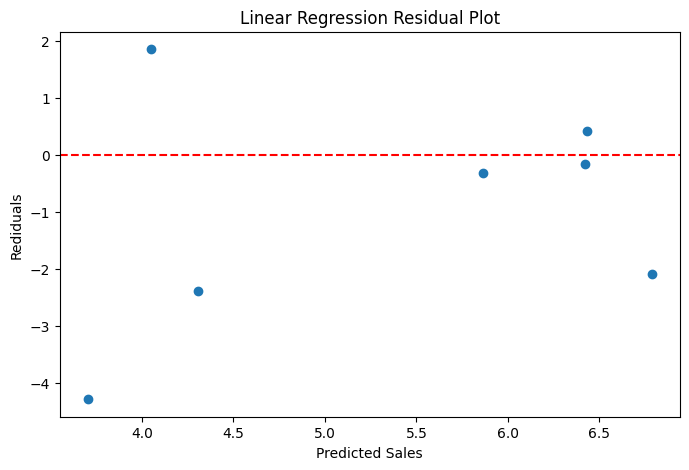

In [12]:
# Plot Residuals for Linear Regression
residuals_lin =Y_test - y_pred_linear
plt.figure(figsize=(8,5))
plt.scatter(x=y_pred_linear,y=residuals_lin)
plt.axhline(0,color='red',linestyle ='--')
plt.title('Linear Regression Residual Plot')
plt.xlabel('Predicted Sales')
plt.ylabel('Rediduals')
plt.show()

In [13]:
# Step 6: Apply Polynomial Regression (Degree 2)

In [14]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2,include_bias=False)

# Create Polynomial features (degree=2) to capture non-linear relationships

X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.fit_transform(X_test)

# This transforms features X into [x,x^2,X^3,....] for better model flexibility
# For first sample = [2,3]:
# Original: [x1=2,x2=3]
# Transformed becomes:
# [x1=2,x2=3,,x1*2=4,x1^x2=6,x2^2 = 9]
# This allows linear regression to model relationships like:
# y= w0*x1 + w1*x2 +w3*x1*x2 + w4*x2^2
# Which can capture curved patterns and features interactions


In [15]:
poly_reg = LinearRegression()
poly_reg.fit(X_poly_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [16]:
# Predict
y_pred_poly = poly_reg.predict(X_poly_test)

In [17]:
# Evaluate Polynomial Model
r2_poly = r2_score(Y_test,y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(Y_test,y_pred_poly))
print("Polynomial Regression: ",round(r2_poly,3))
print("Polynomial Regression RMSE: ", round(rmse_poly,3))

Polynomial Regression:  0.895
Polynomial Regression RMSE:  0.811


In [23]:
# Plot Residual for  Polynomial Regression
residuals_poly = Y_test - y_pred_poly
plt.figure(figsize=(8,5))
sns.scatterplot(x= y_pred_poly, y= residuals_poly)
plt.axhline(0,color = 'red', linestyle ='--')
plt.title('Polynomial Regression Residual Plot')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals')
plt.show()

ValueError: Per-column arrays must each be 1-dimensional

<Figure size 800x500 with 0 Axes>

In [ ]:
# Range is smaller (+- 4.0) in the linear plot), meaning better accuracy

In [21]:
# step 2: Conlusion summary
print('\nModel Comparision:')
print(f'Linear Regression -> : {round(r2_lin,3)}, RMSE:{round(rmse_lin,3)}')
print(f'Polynomial Regression: {round(r2_poly,3)} RMSE: {round(rmse_poly,3)}')


Model Comparision:
Linear Regression -> : 0.269, RMSE:2.144
Polynomial Regression: 0.895 RMSE: 0.811


In [22]:
# Key insight:
# If te polynomial regression shows higher R^2 and lower RMSE and more random residuals,
# it indicates a better fit for nonlinear data